<a href="https://colab.research.google.com/github/Bix4UMD/BIOI611_lab/blob/main/docs/BIOI611_introR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to R

R is a language and environment for statistical computing and graphics. It runs on Windows, macOS, and Linux, and its open-source community develops packages for many kinds of analysis.

In this lab, we will use R to prepare the gene-count tables used in the next RNA-seq lesson. The course data contain six *C. elegans* N2 samples: day-1 and day-7 adults, with three biological replicates per group. The two ages are separate groups, not a continuous time series.

By the end, you should be able to:

- Create and inspect variables, vectors, matrices, data frames, and lists.
- Select rows and columns, and use a function on several files.
- Combine six STAR count tables while keeping gene and sample identifiers aligned.
- Make labeled plots and explain what they show.

Allow about 60–90 minutes for Sections 1–4. Section 5 provides optional ggplot2 practice. Run code cells from top to bottom; later cells use objects created earlier.

## 1. Start an R session

Open this notebook with the Colab button above, or use an R notebook in Jupyter. The notebook specifies an **R** kernel. You can also run its R code in RStudio. The examples are R code, so use an R session to run them. The first command should print an R version.

Sections 1–4 use packages included with R. Section 3 downloads six small count tables from the course repository; it does not require the original FASTQ files or a cluster account. Internet access is needed for that download. Section 5 additionally uses ggplot2.

In a notebook, run a cell with **Shift+Enter**. Text after `#` is a comment. If you restart the session, run the preceding cells again.

In [ ]:
R.version.string
getwd()

### Variables and basic data types

Use `<-` to assign a value to an object. R is case-sensitive: `gene1` and `Gene1` are different names. For ordinary object names, start with a letter (or a dot not followed by a number); letters, numbers, dots, and underscores can follow. Avoid spaces, reserved words such as `if`, and names of functions such as `rep`.

We will use numeric values for counts, character values for names, and logical values (`TRUE` or `FALSE`) for comparisons. `150` is stored as a double-precision number; `150L` explicitly creates an integer.

In [2]:
# Assign two numeric values, then display them.
gene1 <- 150
gene2 <- 200
gene1
gene2

# Character values need quotation marks.
gene_name <- "KRAS"
gene_name

[1] 150


[1] 200


[1] "KRAS"


In [3]:
gene1 > gene2
gene1 < gene2
is_lower <- gene1 < gene2
is_lower

class(gene1)
class(gene_name)
class(is_lower)
class(150L)

[1] FALSE


[1] TRUE


[1] TRUE


[1] "numeric"


[1] "character"


[1] "logical"


[1] "integer"


`<` and `>` compare values; `==` tests equality. `<-` assigns a value. A function call uses a function name followed by parentheses, with arguments inside: `class(gene1)` asks for the class of `gene1`. Try `?class` in an R console to open its help.

**Check your understanding:** What will `gene1 == gene2` return? What changes if you assign `gene2 <- 150`? Restore `gene2 <- 200` afterward.

### Functions

A function is reusable code with named inputs called arguments. This function adds 1 before taking a base-2 logarithm, so a zero count becomes 0 rather than negative infinity. The last expression is returned; `return()` is optional.

In [4]:
log2_transform <- function(x) {
    log2(x + 1)
}

log2_transform(gene1)
log2_transform(0)

[1] 7.238405


[1] 0


## 2. Organize data in R

### Atomic vectors and indexing

An atomic vector holds values of one underlying type. `c()` combines values into a vector. Combining numbers and character strings converts the numbers to character strings. R indexes start at **1**.

In [5]:
sample_names <- c("N2_day1_rep1", "N2_day1_rep2", "N2_day1_rep3",
                  "N2_day7_rep1", "N2_day7_rep2", "N2_day7_rep3")
sample_names
length(sample_names)
sample_names[1]
sample_names[c(1, 4)]

counts <- c(0, 10, 150, 200)
counts[counts >= 100]

[1] "N2_day1_rep1" "N2_day1_rep2" "N2_day1_rep3" "N2_day7_rep1" "N2_day7_rep2"
[6] "N2_day7_rep3"


[1] 6


[1] "N2_day1_rep1"


[1] "N2_day1_rep1" "N2_day7_rep1"


[1] 150 200


### Extract information from sample names

`sub(pattern, replacement, x)` replaces the first match in each string; `gsub()` replaces all matches. Patterns are regular expressions: `[0-9]+` means one or more digits, `$` marks the end, `^` marks the start, and `.*` matches any number of characters. Anchoring the replicate suffix avoids leaving part of a multi-digit replicate number behind.

Here we remove `_rep1`, `_rep2`, or `_rep3` to obtain the group, and keep the digits after `_rep` to obtain the replicate number. This parsing depends on the course naming convention. For other experiments, use a sample sheet supplied with the data.

In [6]:
group <- sub("_rep[0-9]+$", "", sample_names)
replicate_id <- as.integer(sub("^.*_rep", "", sample_names))
group
replicate_id

[1] "N2_day1" "N2_day1" "N2_day1" "N2_day7" "N2_day7" "N2_day7"


[1] 1 2 3 1 2 3


### Matrices and data frames

A matrix has rows and columns. An **atomic matrix** uses one underlying type for every entry, so combining character groups with integer replicate numbers makes all entries character. `cbind()` combines columns; `rownames()` assigns row labels; `t()` swaps rows and columns.

In [7]:
sample_matrix <- cbind(group = group, replicate = replicate_id)
rownames(sample_matrix) <- sample_names
sample_matrix
is.matrix(sample_matrix)
str(sample_matrix)
t(sample_matrix)

             group     replicate
N2_day1_rep1 "N2_day1" "1"      
N2_day1_rep2 "N2_day1" "2"      
N2_day1_rep3 "N2_day1" "3"      
N2_day7_rep1 "N2_day7" "1"      
N2_day7_rep2 "N2_day7" "2"      
N2_day7_rep3 "N2_day7" "3"      


[1] TRUE


 chr [1:6, 1:2] "N2_day1" "N2_day1" "N2_day1" "N2_day7" "N2_day7" "N2_day7" ...
 - attr(*, "dimnames")=List of 2
  ..$ : chr [1:6] "N2_day1_rep1" "N2_day1_rep2" "N2_day1_rep3" "N2_day7_rep1" ...
  ..$ : chr [1:2] "group" "replicate"


          N2_day1_rep1 N2_day1_rep2 N2_day1_rep3 N2_day7_rep1 N2_day7_rep2
group     "N2_day1"    "N2_day1"    "N2_day1"    "N2_day7"    "N2_day7"   
replicate "1"          "2"          "3"          "1"          "2"         
          N2_day7_rep3
group     "N2_day7"   
replicate "3"         


A data frame lets different columns retain different types. It is a better choice for sample metadata. Construct it directly so the replicate column stays integer. A factor represents categories; setting its levels explicitly makes day 1 the reference level for a later comparison.

Replicate numbers label biological replicates **within each group**. Matching replicate numbers across groups do not establish pairing.

In [8]:
coldata_df <- data.frame(
    group = factor(group, levels = c("N2_day1", "N2_day7")),
    replicate = replicate_id,
    row.names = sample_names
)
coldata_df
is.data.frame(coldata_df)
str(coldata_df)
table(coldata_df$group)

               group replicate
N2_day1_rep1 N2_day1         1
N2_day1_rep2 N2_day1         2
N2_day1_rep3 N2_day1         3
N2_day7_rep1 N2_day7         1
N2_day7_rep2 N2_day7         2
N2_day7_rep3 N2_day7         3


[1] TRUE


'data.frame':	6 obs. of  2 variables:
 $ group    : Factor w/ 2 levels "N2_day1","N2_day7": 1 1 1 2 2 2
 $ replicate: int  1 2 3 1 2 3



N2_day1 N2_day7 
      3       3 


For a data frame, use `object[rows, columns]`. Leaving either position blank keeps all of those rows or columns. `$` selects a named column. `drop = FALSE` keeps a single-column selection as a data frame.

In [9]:
coldata_df[1:3, , drop = FALSE]
coldata_df[, "group", drop = FALSE]
coldata_df[coldata_df$group == "N2_day7", , drop = FALSE]

               group replicate
N2_day1_rep1 N2_day1         1
N2_day1_rep2 N2_day1         2
N2_day1_rep3 N2_day1         3


               group
N2_day1_rep1 N2_day1
N2_day1_rep2 N2_day1
N2_day1_rep3 N2_day1
N2_day7_rep1 N2_day7
N2_day7_rep2 N2_day7
N2_day7_rep3 N2_day7


               group replicate
N2_day7_rep1 N2_day7         1
N2_day7_rep2 N2_day7         2
N2_day7_rep3 N2_day7         3


### Missing values

`NA` represents a missing value, which is different from a measured count of zero. Use `is.na()` to find missing values. The example below shows how `na.rm = TRUE` changes a summary; decide why a value is missing before excluding it from an analysis.

In [10]:
example_counts <- c(0, 10, NA, 20)
is.na(example_counts)
mean(example_counts)
mean(example_counts, na.rm = TRUE)

[1] FALSE FALSE  TRUE FALSE


[1] NA


[1] 10


### Lists and `lapply()`

A list can hold objects of different types, including vectors and data frames. `lapply()` calls a function once on each list element and returns a list. Here the inputs are two count vectors. `[[1]]` extracts the first list element; `[1]` returns a list containing that element.

In [11]:
gene_counts <- list(gene1 = c(10, 20), gene2 = c(0, 100))
gene_counts[[1]]
lapply(gene_counts, log2_transform)

[1] 10 20


$gene1
[1] 3.459432 4.392317

$gene2
[1] 0.000000 6.658211



**Check your understanding:** Why did the replicate numbers become character values in `sample_matrix`? Which data-frame expression selects the three day-1 samples?

## 3. Read and combine STAR count files

### Download the course tables

`getwd()` shows the current working directory. Relative paths are interpreted from that directory. We will store this lesson's inputs in `introR_counts/`, using `file.path()` so paths work across operating systems.

The download uses a fixed repository revision to keep the example data reproducible. Existing files are reused. If you already have a local repository checkout, you can instead set `data_dir` to its `data/bulkRNA_SE_tab` directory before running this cell.

In [12]:
data_dir <- "introR_counts"
dir.create(data_dir, showWarnings = FALSE, recursive = TRUE)
file_suffix <- ".ReadsPerGene.out.tab"
expected_files <- paste0(sample_names, file_suffix)
data_revision <- "3ae91df81a2849a69b90157c4e75f6f8089cd44b"
base_url <- paste0("https://raw.githubusercontent.com/Bix4UMD/BIOI611_lab/",
                   data_revision, "/data/bulkRNA_SE_tab/")

for (filename in expected_files) {
    destination <- file.path(data_dir, filename)
    if (!file.exists(destination)) {
        download.file(paste0(base_url, filename), destfile = destination,
                      mode = "wb", quiet = TRUE)
    }
}
list.files(data_dir)

[1] "N2_day1_rep1.ReadsPerGene.out.tab" "N2_day1_rep2.ReadsPerGene.out.tab"
[3] "N2_day1_rep3.ReadsPerGene.out.tab" "N2_day7_rep1.ReadsPerGene.out.tab"
[5] "N2_day7_rep2.ReadsPerGene.out.tab" "N2_day7_rep3.ReadsPerGene.out.tab"


`list.files(pattern = ...)` expects a regular expression rather than a shell wildcard. In an R string, `\\.` matches a literal dot. The final `$` requires the filename to end at `.tab`.

We check that all six expected files are present and put them in the same order as `sample_names`. `stopifnot()` stops with an error if any check is false.

In [13]:
file_paths <- list.files(
    data_dir,
    pattern = "\\.ReadsPerGene\\.out\\.tab$",
    full.names = TRUE
)
stopifnot(setequal(basename(file_paths), expected_files))
file_paths <- file_paths[match(expected_files, basename(file_paths))]
file_paths

[1] "introR_counts/N2_day1_rep1.ReadsPerGene.out.tab"
[2] "introR_counts/N2_day1_rep2.ReadsPerGene.out.tab"
[3] "introR_counts/N2_day1_rep3.ReadsPerGene.out.tab"
[4] "introR_counts/N2_day7_rep1.ReadsPerGene.out.tab"
[5] "introR_counts/N2_day7_rep2.ReadsPerGene.out.tab"
[6] "introR_counts/N2_day7_rep3.ReadsPerGene.out.tab"


### Inspect one file before writing a function

STAR's `ReadsPerGene.out.tab` has no header and contains four tab-separated columns:

| Column | Meaning |
| --- | --- |
| 1 | Gene identifier, or a summary-row label |
| 2 | Counts without considering strand |
| 3 | Counts when read 1 is on the same strand as the RNA |
| 4 | Counts when read 1 is on the opposite strand to the RNA |

For single-end data, read 1 is the sequenced read. For paired-end data, the read-2 orientation is opposite. The first four rows are summaries (`N_unmapped`, `N_multimapping`, `N_noFeature`, `N_ambiguous`), not genes. See the [STAR manual, gene-counting section](https://github.com/alexdobin/STAR/blob/2.7.11b/doc/STARmanual.pdf).

We use column 2 for this **R programming exercise**, matching the existing course examples. Before biological analysis, confirm the library protocol and strandedness to choose the appropriate count column. This notebook does not establish the strandedness of these libraries.

In [14]:
star_table <- read.table(file_paths[1], header = FALSE, sep = "\t",
                         stringsAsFactors = FALSE)
head(star_table)
dim(star_table)
str(star_table)

              V1      V2       V3       V4
1     N_unmapped 1332776  1332776  1332776
2 N_multimapping 1540190  1540190  1540190
3    N_noFeature  157102 19017455 18933214
4    N_ambiguous  536422   128854   120342
5 WBGene00000003     341      161      180
6 WBGene00000007     416      215      202


[1] 46930     4


'data.frame':	46930 obs. of  4 variables:
 $ V1: chr  "N_unmapped" "N_multimapping" "N_noFeature" "N_ambiguous" ...
 $ V2: int  1332776 1540190 157102 536422 341 416 0 6 1572 0 ...
 $ V3: int  1332776 1540190 19017455 128854 161 215 0 4 814 0 ...
 $ V4: int  1332776 1540190 18933214 120342 180 202 0 2 794 0 ...


### Turn a repeated task into a function

The function below reads one file, keeps the selected count column, removes the four summary labels by name, and names the count column after the sample. Checks catch a malformed table, duplicate gene identifiers, or invalid counts before combining files. They should stop the analysis rather than silently turn missing data into zeros.

`count_column = 2L` supplies a default argument. For a verified stranded protocol, the appropriate value may be `3L` or `4L`. `return(df)` makes the result explicit.

In [15]:
read_star_file <- function(file_path, count_column = 2L) {
    stopifnot(length(count_column) == 1L, count_column %in% 2:4)
    df <- read.table(file_path, header = FALSE, sep = "\t",
                     stringsAsFactors = FALSE)
    stopifnot(ncol(df) == 4L)
    df <- df[, c(1L, count_column), drop = FALSE]
    summary_rows <- c("N_unmapped", "N_multimapping",
                      "N_noFeature", "N_ambiguous")
    stopifnot(all(summary_rows %in% df[[1]]))
    df <- df[!df[[1]] %in% summary_rows, , drop = FALSE]
    stopifnot(nrow(df) > 0L, !anyNA(df), !anyDuplicated(df[[1]]),
              is.numeric(df[[2]]), all(is.finite(df[[2]])),
              all(df[[2]] >= 0), all(df[[2]] == floor(df[[2]])))
    sample_id <- sub("\\.ReadsPerGene\\.out\\.tab$", "", basename(file_path))
    colnames(df) <- c("GeneID", sample_id)
    return(df)
}

tab_N2_day1_rep1 <- read_star_file(file_paths[1])
head(tab_N2_day1_rep1)
dim(tab_N2_day1_rep1)

           GeneID N2_day1_rep1
5  WBGene00000003          341
6  WBGene00000007          416
7  WBGene00000014            0
8  WBGene00000015            6
9  WBGene00000022         1572
10 WBGene00000024            0


[1] 46926     2


### Merge two tables by gene identifier

`merge(..., by = "GeneID")` matches identifiers, so it does not assume that the input rows have the same order. Its default is an inner join: genes missing from either table would be dropped. We first require the same gene set. Unique sample-column names also avoid confusing names such as `V2.x` and `V2.y`.

In [16]:
tab_N2_day1_rep2 <- read_star_file(file_paths[2])
stopifnot(setequal(tab_N2_day1_rep1$GeneID, tab_N2_day1_rep2$GeneID))
two_samples <- merge(tab_N2_day1_rep1, tab_N2_day1_rep2, by = "GeneID")
head(two_samples)

          GeneID N2_day1_rep1 N2_day1_rep2
1 WBGene00000001         3227         2168
2 WBGene00000002          270          203
3 WBGene00000003          341          415
4 WBGene00000004          584          438
5 WBGene00000005          383          395
6 WBGene00000006          343          344


### Apply the same steps to all six samples

`lapply()` reads each file into a list of data frames. `Reduce()` repeatedly merges the next table into the accumulated result. Check that every table has the same gene set **before** the inner joins.

This cell is a worked example: focus first on the inputs, the result, and why the checks matter. You can return to the anonymous `function(x, y)` syntax after practicing with two tables.

In [17]:
list_of_dfs <- lapply(file_paths, read_star_file)
same_genes <- vapply(list_of_dfs, function(df) {
    setequal(df$GeneID, list_of_dfs[[1]]$GeneID)
}, logical(1))
stopifnot(all(same_genes))

merged_df <- Reduce(function(x, y) merge(x, y, by = "GeneID"), list_of_dfs)
merged_df <- merged_df[, c("GeneID", sample_names), drop = FALSE]
head(merged_df)
dim(merged_df)

          GeneID N2_day1_rep1 N2_day1_rep2 N2_day1_rep3 N2_day7_rep1
1 WBGene00000001         3227         2168         2589         5659
2 WBGene00000002          270          203          266          355
3 WBGene00000003          341          415          411          387
4 WBGene00000004          584          438          518         1028
5 WBGene00000005          383          395          483          119
6 WBGene00000006          343          344          334          206
  N2_day7_rep2 N2_day7_rep3
1         2619         5239
2          191          425
3          255          499
4          541          888
5           65          189
6          114          220


[1] 46926     7


### Prepare the count matrix and sample metadata

For the next lesson, genes are rows of the count matrix and samples are columns. Sample metadata have one row per sample. The matrix column names must match metadata row names **in the same order**. Keep gene identifiers as row names, outside the numeric matrix.

`merged_df` remains a table with a `GeneID` column; `count_matrix` contains only raw gene counts. These objects have different roles. DESeq2 expects raw, non-negative whole-number counts, not TPM, percentages, or the `log2(count + 1)` values used for display.

In [18]:
count_matrix <- as.matrix(merged_df[, sample_names, drop = FALSE])
rownames(count_matrix) <- merged_df$GeneID
coldata_df <- coldata_df[colnames(count_matrix), , drop = FALSE]

stopifnot(is.numeric(count_matrix), !anyNA(count_matrix),
          all(count_matrix >= 0),
          all(count_matrix == floor(count_matrix)),
          identical(colnames(count_matrix), rownames(coldata_df)))
dim(count_matrix)
table(coldata_df$group)
identical(colnames(count_matrix), rownames(coldata_df))

[1] 46926     6



N2_day1 N2_day7 
      3       3 


[1] TRUE


For these files, expect **46,926 gene rows and 6 sample columns**, three samples in each group, and `TRUE` for the ordering check. This row count describes this particular annotation; it is not a universal expected number of genes.

The following files are saved to an `introR_results/` directory. `row.names = FALSE` avoids writing an extra numbered column to the count CSV. The metadata CSV deliberately includes sample identifiers as row names.

In [19]:
results_dir <- "introR_results"
dir.create(results_dir, showWarnings = FALSE, recursive = TRUE)
write.csv(merged_df, file.path(results_dir, "combined_gene_counts.csv"),
          row.names = FALSE)
write.csv(coldata_df, file.path(results_dir, "sample_metadata.csv"),
          row.names = TRUE)
saveRDS(list(count_matrix = count_matrix, coldata = coldata_df),
        file.path(results_dir, "introR_counts_and_metadata.rds"))

**Check your understanding:** Why should the four STAR summary rows be excluded? Why is attaching counts with `cbind()` unsafe if gene orders differ? Why does a zero count mean something different from `NA`?

## 4. Produce graphs with base R

### Plot a summary of the course data

`colSums()` adds counts across gene rows for each sample. These are **assigned gene counts**, not total sequenced reads: unmapped, ambiguous, and other unassigned reads are excluded. Differences may reflect sequencing depth and other technical or biological effects. This plot is a preliminary check, not a differential-expression test.

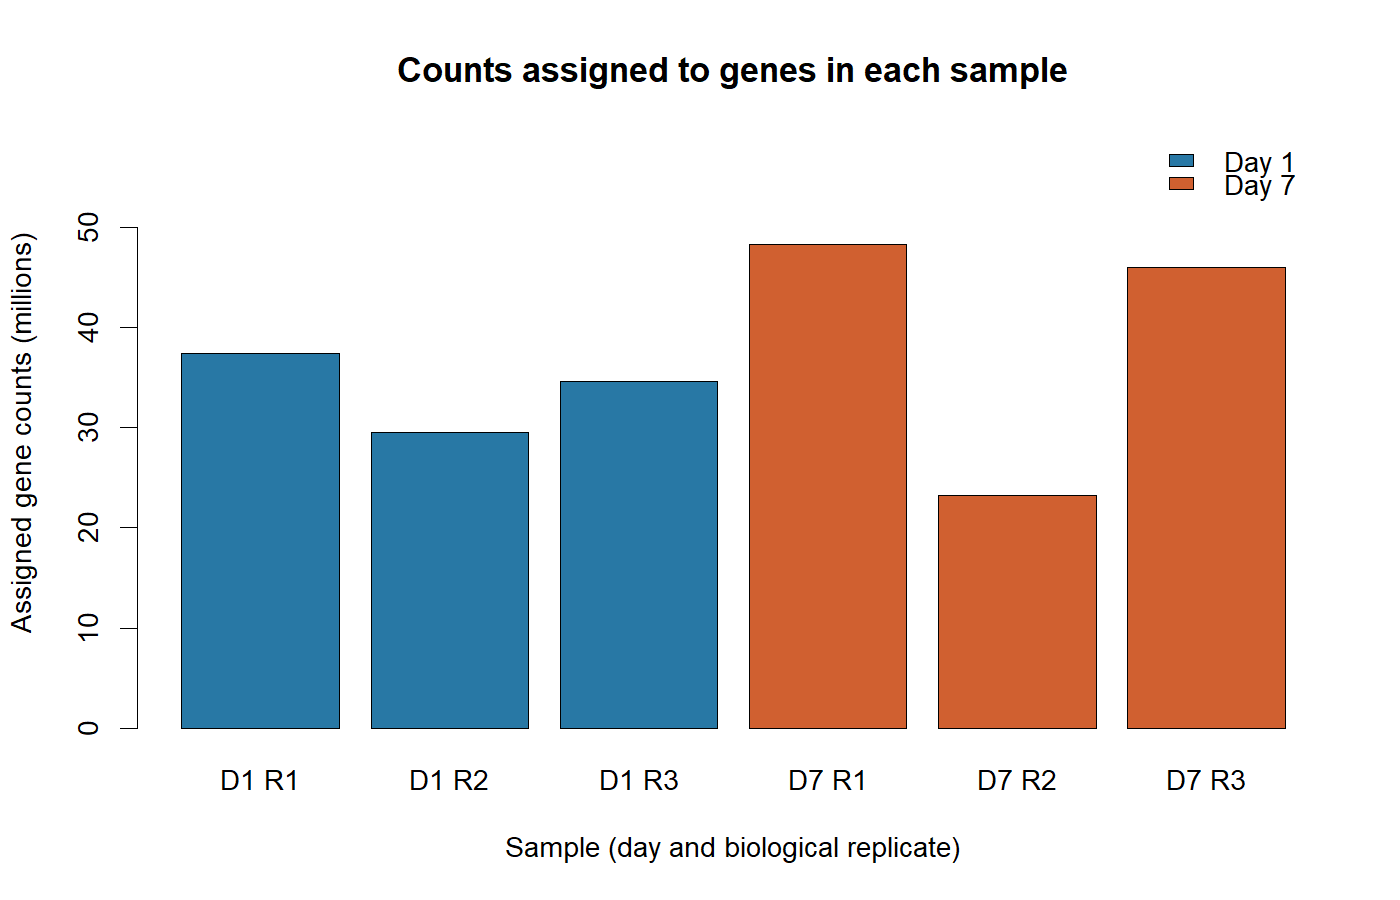

In [20]:
assigned_counts <- colSums(count_matrix)
group_colors <- c(N2_day1 = "#2878A5", N2_day7 = "#D06030")
sample_colors <- unname(group_colors[as.character(coldata_df$group)])

barplot(assigned_counts / 1e6,
        names.arg = c("D1 R1", "D1 R2", "D1 R3", "D7 R1", "D7 R2", "D7 R3"),
        col = sample_colors,
        ylim = c(0, max(assigned_counts / 1e6) * 1.22),
        main = "Counts assigned to genes in each sample",
        xlab = "Sample (day and biological replicate)",
        ylab = "Assigned gene counts (millions)")
legend("topright", legend = c("Day 1", "Day 7"), fill = group_colors,
       bty = "n")

### Points and lines

Use lines when the x-axis represents an ordered quantity such as time. The following values are **synthetic plotting practice**, separate from the RNA-seq samples. `type = "o"` draws both points and connecting lines. `lines()` adds a series to the existing plot.

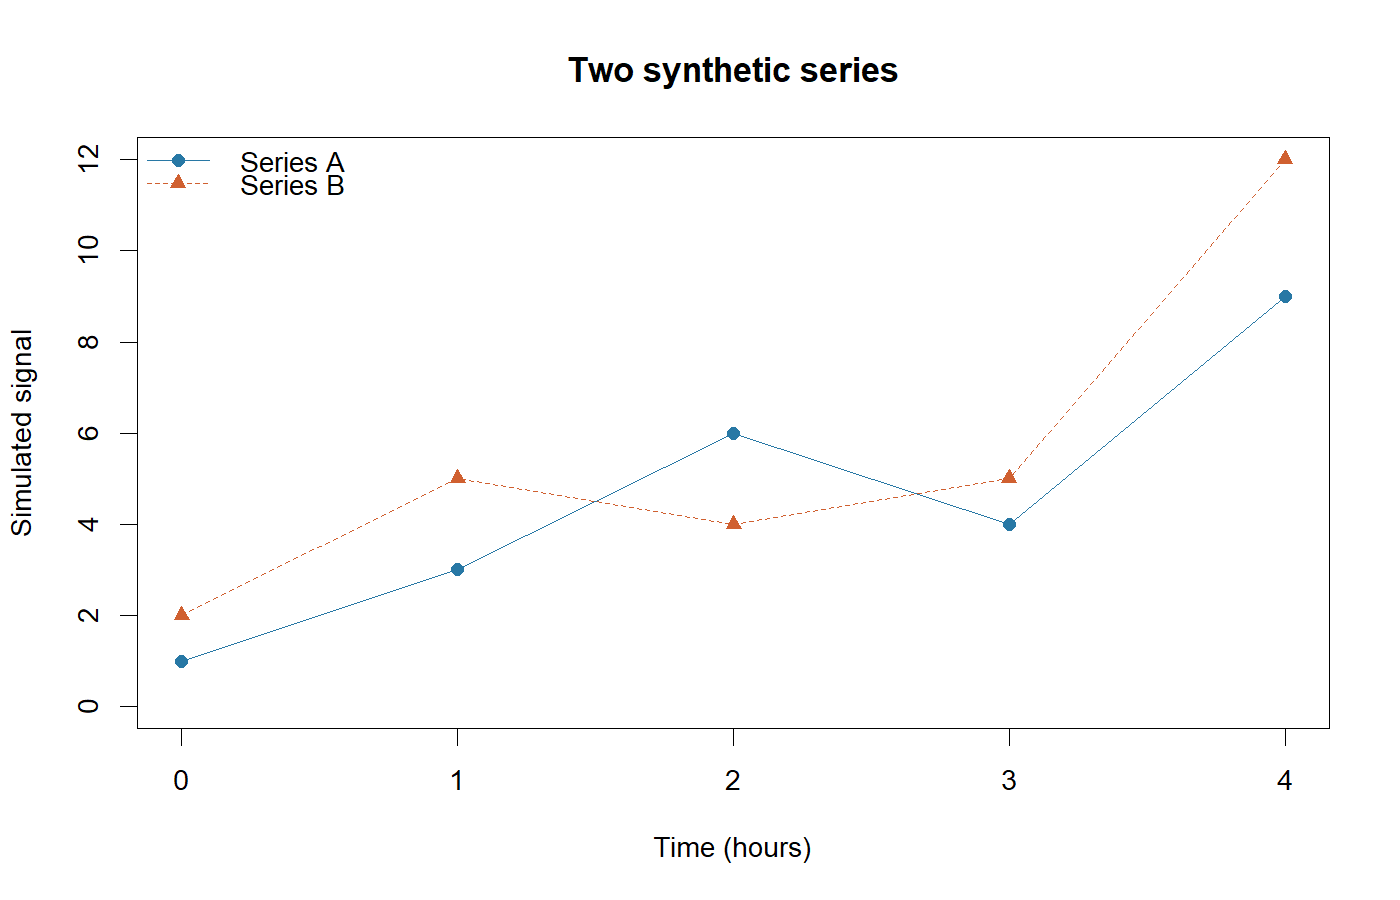

In [21]:
time_hours <- c(0, 1, 2, 3, 4)
series_a <- c(1, 3, 6, 4, 9)
series_b <- c(2, 5, 4, 5, 12)

plot(time_hours, series_a, type = "o", col = "#2878A5", pch = 16,
     ylim = c(0, 12), xlab = "Time (hours)", ylab = "Simulated signal",
     main = "Two synthetic series")
lines(time_hours, series_b, type = "o", col = "#D06030", pch = 17, lty = 2)
legend("topleft", legend = c("Series A", "Series B"),
       col = c("#2878A5", "#D06030"), pch = c(16, 17), lty = c(1, 2),
       bty = "n")

### Scatterplots

We use R's built-in `mtcars` dataset for plotting practice, so no additional download is needed. It describes 32 cars; `wt` is weight in **1,000 pounds**, and `mpg` is miles per US gallon. Row names contain car model names.

`lm(mpg ~ wt, data = mtcars)` fits a straight-line relationship. Its line summarizes an association, which by itself does not establish causation.

                   mpg cyl disp  hp drat    wt  qsec vs am gear carb
Mazda RX4         21.0   6  160 110 3.90 2.620 16.46  0  1    4    4
Mazda RX4 Wag     21.0   6  160 110 3.90 2.875 17.02  0  1    4    4
Datsun 710        22.8   4  108  93 3.85 2.320 18.61  1  1    4    1
Hornet 4 Drive    21.4   6  258 110 3.08 3.215 19.44  1  0    3    1
Hornet Sportabout 18.7   8  360 175 3.15 3.440 17.02  0  0    3    2
Valiant           18.1   6  225 105 2.76 3.460 20.22  1  0    3    1


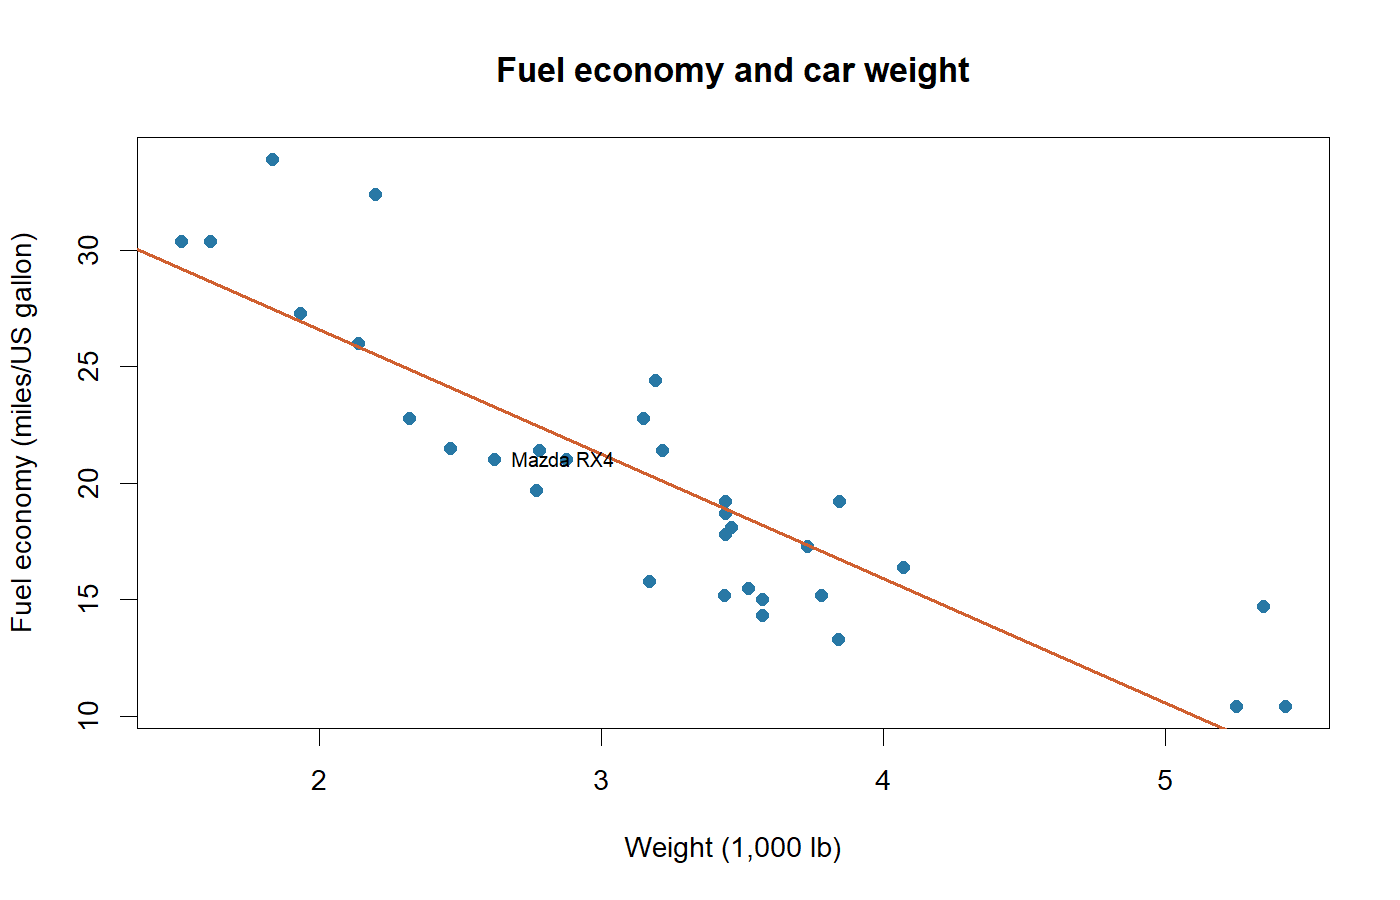

In [22]:
mtcars <- datasets::mtcars
head(mtcars)

plot(mtcars$wt, mtcars$mpg,
     main = "Fuel economy and car weight",
     xlab = "Weight (1,000 lb)", ylab = "Fuel economy (miles/US gallon)",
     pch = 16, col = "#2878A5")
abline(lm(mpg ~ wt, data = mtcars), col = "#D06030", lwd = 2)
# Label one example to keep the figure readable.
text(mtcars$wt[1], mtcars$mpg[1], labels = rownames(mtcars)[1],
     pos = 4, cex = 0.7)

### Histograms and density

`probability = TRUE` scales the histogram so the **sum of bar areas** is 1. A bar's area (height × width) is the fraction of observations in its interval; its height alone is a density, not a probability. `density()` adds a smoothed estimate of the distribution. The dashed vertical line marks the mean.

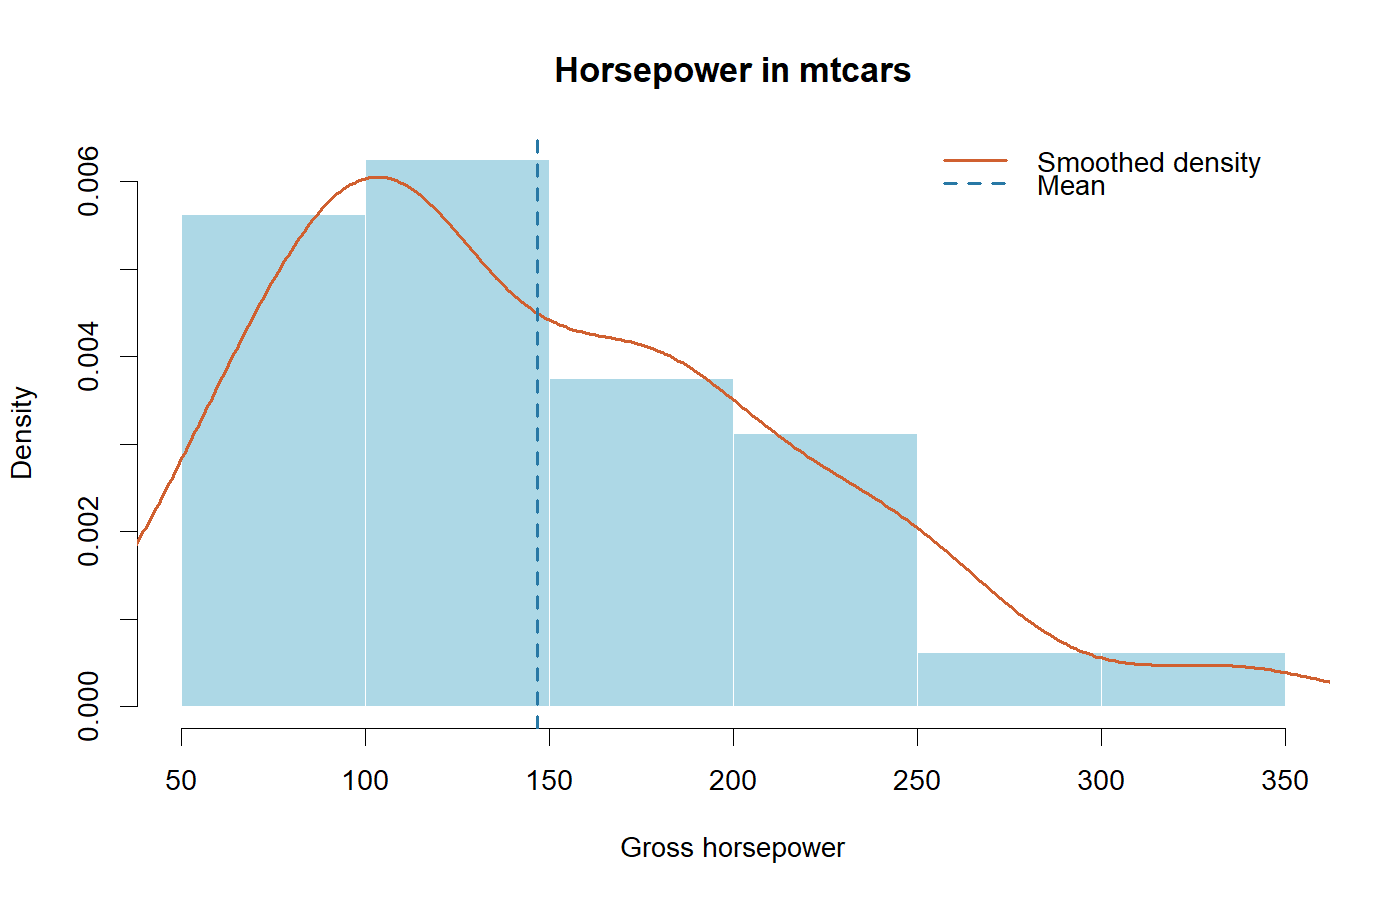

In [23]:
hist(mtcars$hp, probability = TRUE, breaks = 6,
     main = "Horsepower in mtcars", xlab = "Gross horsepower",
     ylab = "Density", col = "lightblue", border = "white")
lines(density(mtcars$hp), lwd = 2, col = "#D06030")
abline(v = mean(mtcars$hp), lty = "dashed", col = "#2878A5", lwd = 2)
legend("topright", legend = c("Smoothed density", "Mean"),
       col = c("#D06030", "#2878A5"), lty = c(1, 2), lwd = 2, bty = "n")

### Save a figure

`png()` opens a graphics file. Draw the plot while that device is open, then call `dev.off()` to finish writing the file. Look in `introR_results/` for the saved image.

In [ ]:
png(file.path(results_dir, "mtcars_weight_mpg.png"),
    width = 1600, height = 1000, res = 200)
plot(mtcars$wt, mtcars$mpg, pch = 16, col = "#2878A5",
     main = "Fuel economy and car weight",
     xlab = "Weight (1,000 lb)", ylab = "Fuel economy (miles/US gallon)")
abline(lm(mpg ~ wt, data = mtcars), col = "#D06030", lwd = 2)
dev.off()

## 5. Optional: produce graphs with ggplot2

Install ggplot2 once in your R environment if needed, then load it for the session. The examples use `after_stat()` for calculated density and `linewidth` for line thickness (ggplot2 3.4.0 or later).

`ggplot(data, aes(...))` chooses data and maps columns to axes. Add layers with `+`. A fixed color goes outside `aes()`; mapping a column to color inside `aes()` creates groups and a legend.

In [ ]:
if (!requireNamespace("ggplot2", quietly = TRUE)) {
    install.packages("ggplot2", repos = "https://cloud.r-project.org")
}
stopifnot(packageVersion("ggplot2") >= "3.4.0")
library(ggplot2)

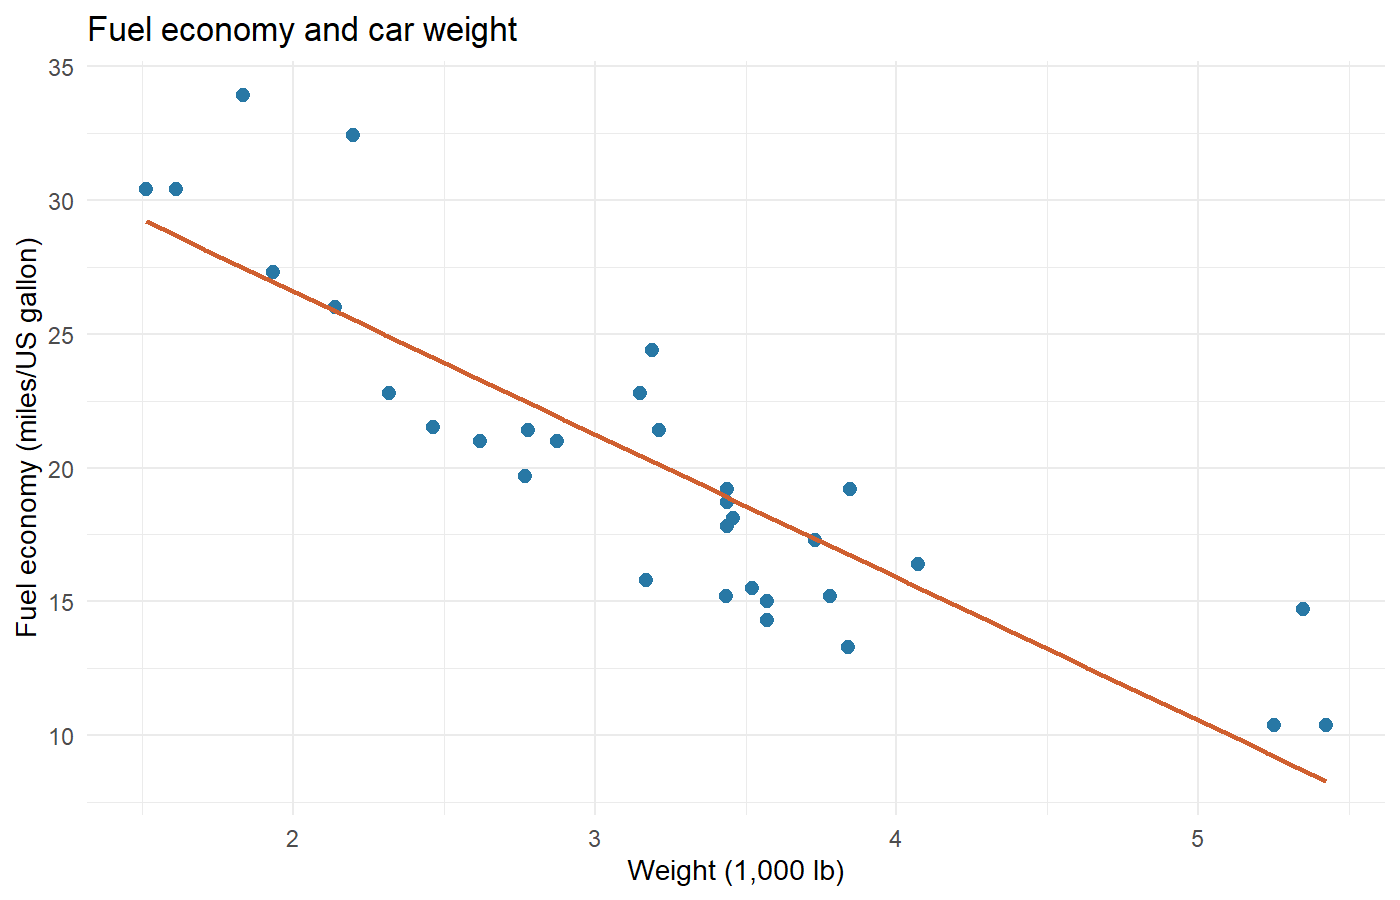

In [26]:
scatter_plot <- ggplot(mtcars, aes(x = wt, y = mpg)) +
    geom_point(size = 2.5, color = "#2878A5") +
    geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
                color = "#D06030", linewidth = 0.8) +
    labs(title = "Fuel economy and car weight",
         x = "Weight (1,000 lb)", y = "Fuel economy (miles/US gallon)") +
    theme_minimal(base_size = 12)
scatter_plot

`se = FALSE` omits the confidence band so this scatterplot matches the base-R example. The histogram below uses the same density scale as its smoothed curve. Changing the bins or smoothing bandwidth can change the appearance; describe the pattern without treating the smooth curve as the exact population distribution.

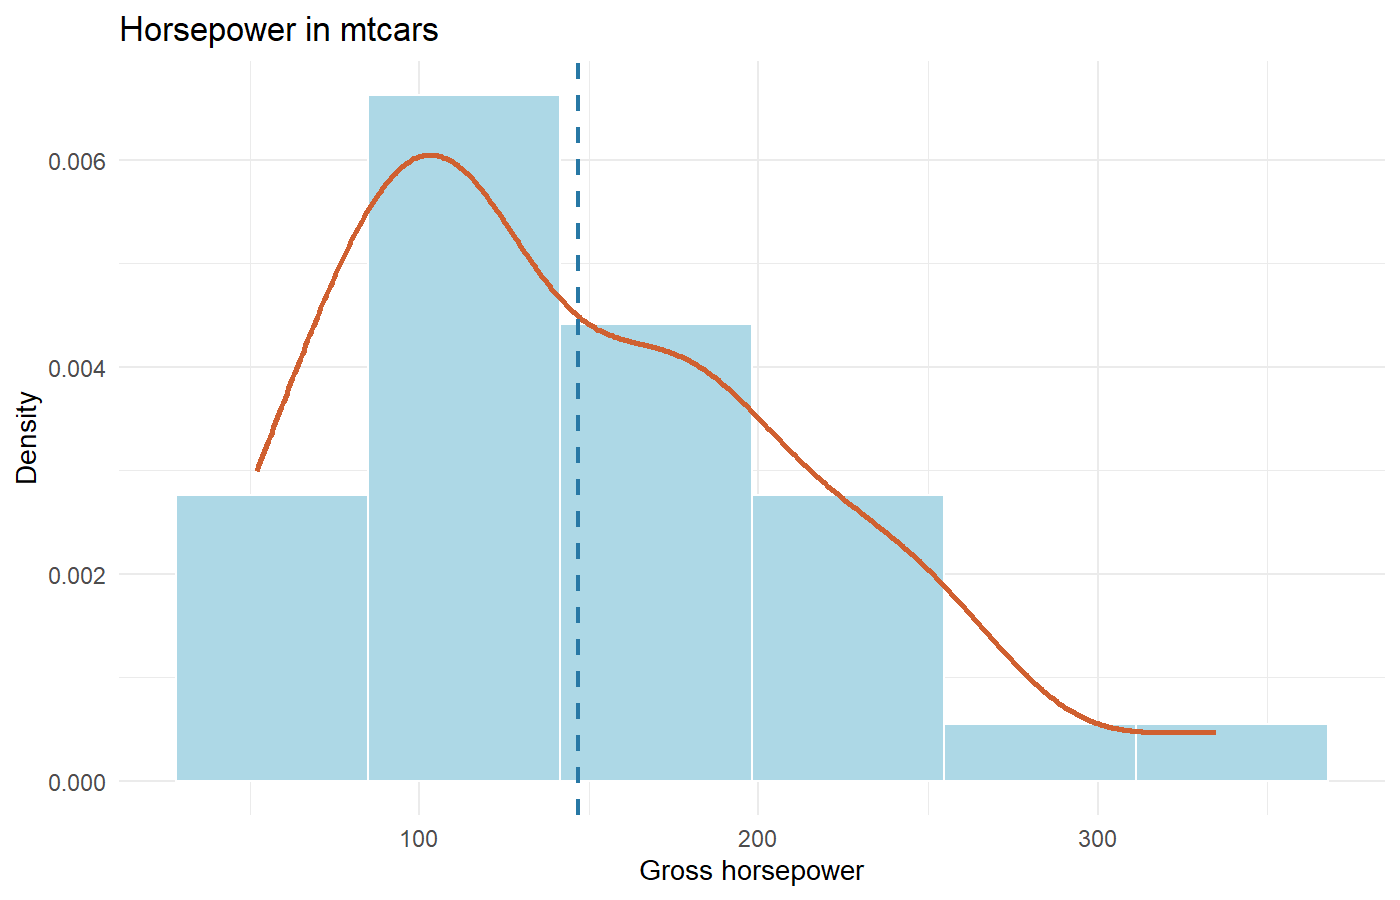

In [27]:
density_plot <- ggplot(mtcars, aes(x = hp)) +
    geom_histogram(aes(y = after_stat(density)), bins = 6,
                   fill = "lightblue", color = "white") +
    geom_density(color = "#D06030", linewidth = 1) +
    geom_vline(xintercept = mean(mtcars$hp), linetype = "dashed",
               color = "#2878A5", linewidth = 0.8) +
    labs(title = "Horsepower in mtcars", x = "Gross horsepower", y = "Density") +
    theme_minimal(base_size = 12)
density_plot

ggsave(file.path(results_dir, "mtcars_ggplot_scatter.png"), plot = scatter_plot,
       width = 7, height = 4.5, dpi = 200)

## Practice and completion checks

Before moving on, check that your count matrix has 46,926 rows and six columns, that there are three samples per group, and that the sample-order check returns `TRUE`. Confirm that the two CSV files, RDS file, and base-R PNG exist in `introR_results/`.

1. Use `coldata_df` to select the day-7 sample names. How many are there?
2. Count genes with at least 10 raw counts in at least three samples. Explain what the two comparisons in your code select.
3. Change the point color and title of a scatterplot, then save it with a new filename.
4. Explain why neither unequal assigned-count totals nor a high raw count is sufficient evidence for differential expression.

Record the R and package versions used for your work. If you skipped Section 5, run the final cell anyway.

In [ ]:
capture.output(sessionInfo(), file = file.path(results_dir, "sessionInfo.txt"))
sessionInfo()

### Hints for practice

Try the questions before opening the hints.

<details>
<summary>Show hints for questions 1 and 2</summary>

```r
# 1. Extract row names after selecting the group.
day7_samples <- rownames(coldata_df)[coldata_df$group == "N2_day7"]
day7_samples
length(day7_samples)

# 2. First compare each gene-by-sample count with 10.
#    Then count qualifying samples for each gene, and require at least three.
keep <- rowSums(count_matrix >= 10) >= 3
sum(keep)
```

This is an example expression filter. The next analysis lesson should explain and justify the filter it uses. A raw-count threshold is not a significance test.

</details>

### Troubleshooting

| Message or symptom | What to check |
| --- | --- |
| `object ... not found` | Run the cell that creates the object; check spelling and capitalization. After a restart, run from the beginning. |
| Cannot open a count file | Check `getwd()`, `data_dir`, internet access, and the download cell. |
| File-list check fails | The selected directory must contain exactly the six expected count tables. Check filenames and use a separate directory for other experiments. |
| Gene-set or duplicate-identifier check fails | Check whether files use the same annotation and whether an input was truncated or edited. Do not remove the check to force a merge. |
| Sample-order check is `FALSE` | Match count-matrix column names to metadata row names before analysis. |
| ggplot2 version check fails | Update ggplot2, restart R if it was already loaded, then run the notebook again. |

## References

- [R: An Introduction to R](https://cran.r-project.org/doc/manuals/r-release/R-intro.html)
- [R: valid object names](https://stat.ethz.ch/R-manual/R-devel/library/base/html/make.names.html)
- [R: file listing and regular expressions](https://stat.ethz.ch/R-manual/R-devel/library/base/html/list.files.html)
- [R: merging data frames](https://stat.ethz.ch/R-manual/R-devel/library/base/html/merge.html)
- [STAR manual: gene counts and strand conventions](https://github.com/alexdobin/STAR/blob/2.7.11b/doc/STARmanual.pdf)
- [R: the built-in mtcars dataset](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/mtcars.html)
- [R: histogram density scaling](https://stat.ethz.ch/R-manual/R-devel/library/graphics/html/hist.html)
- [ggplot2: calculated aesthetics and after_stat()](https://ggplot2.tidyverse.org/reference/aes_eval.html)
- [ggplot2: density plots](https://ggplot2.tidyverse.org/reference/geom_density.html)

Additional plotting tutorials used in the earlier version of this lesson:

- [F. McCown: Producing Simple Graphs with R](https://sites.harding.edu/fmccown/R/)
- [Base R vs. ggplot2 visualization](https://jtr13.github.io/cc21fall2/base-r-vs.-ggplot2-visualization.html#base-r-vs.-ggplot2-visualization)